# Solving the two orders

<div class="alert alert-info">

**Summary**

In this lesson the reader builds both orders of the portfolio–consumption model from their files, supplies the value after the last period, solves each order with a method chosen for each stage, recovers one order's value from the other's, and changes the method of one stage. The objects inspected are the consumption rule, the risky share and the check behind each claim. This lesson solves.

</div>

<div class="alert alert-success">

**Relationship with other documents**

**Builds on** — [Two stages, two orders](01-two-stages-two-orders.ipynb) and [A life cycle built backwards](02-a-life-cycle-built-backwards.ipynb): the two orders and their trellis files.

**Formal account** — [Periods](../../../docs/Bellman-Sym/06-period.md) and [Trellises](../../../docs/Bellman-Sym/07-trellis.md): the period written once, and the trellis indexed back from its last period.

**See also** — [The portfolio–consumption application](../../../applications/cons-port/README.md): the tool and its acceptance test.

</div>

<div class="alert">

**Key terminology**

| Term | Meaning |
|---|---|
| [[handler]] | The function of an application's tool that carries a method out. |
| [[trellis]] | A model's sequence of periods, built backwards from the last. |
| [[specified_stage\|specified]] | Said of a stage bound to its values, methods and settings. |

</div>

A household lives six years. Each year it consumes $\mathrm{c}$ out of its resources $\mathrm{m}$, with utility $u(\mathrm{c}) = \mathrm{c}^{1-\rho}/(1-\rho)$ and discount factor $\beta$, and invests its savings, the share $\varsigma$ in a risky asset with gross return $\Psi$ and the rest at the safe gross return $R$; the return and transitory income $\theta$ are drawn after the share is chosen. The periods of the model's [[trellis]] hold the portfolio [[stage]] first or consumption first, and the two orders differ in where the year ends. Write $V_h$ for the value at the portfolio decision, a function of capital $\mathrm{k}$, and $W_h$ for the value at the consumption decision, a function of resources, in the year $h$ years before the last, $h = 0, \dots, 5$.

Portfolio first, the year begins with the portfolio choice and ends on savings:

$$
V_h(\mathrm{k}) = \max_{\varsigma \in [0, 1]} \mathbb{E}\big[W_h\big(\mathrm{k}(\varsigma\Psi + (1 - \varsigma)R) + \theta\big)\big], \qquad
W_h(\mathrm{m}) = \max_{\mathrm{c} \in (0, \mathrm{m}]} u(\mathrm{c}) + \beta V_{h-1}(\mathrm{m} - \mathrm{c}),
$$

with $V_{-1}(\mathrm{a}) = u(\mathrm{a})$: the value after the last period is taken on savings.

Consumption first, the year boundary falls after the draw:

$$
W_h(\mathrm{m}) = \max_{\mathrm{c} \in (0, \mathrm{m}]} u(\mathrm{c}) + \beta V_h(\mathrm{m} - \mathrm{c}), \qquad
V_h(\mathrm{k}) = \max_{\varsigma \in [0, 1]} \mathbb{E}\big[W_{h-1}\big(\mathrm{k}(\varsigma\Psi + (1 - \varsigma)R) + \theta\big)\big],
$$

with $W_{-1}(\mathrm{m}) = u(\mathrm{m})$: the value after the last period is taken on next year's resources.

| Written | Meaning |
|---|---|
| `m_d`, `c` | resources $\mathrm{m}_d$ at the consumption decision, and consumption $\mathrm{c}$ |
| `k_d`, `ς` | capital $\mathrm{k}_d$ at the portfolio decision, and the risky share $\varsigma$ |
| `Ψ`, `β`, `ρ` | the risky gross return $\Psi$, the discount factor $\beta$, relative risk aversion $\rho$ |
| `h` | the period $h$ years before the last; $h = 0$ is the last |

The lesson reads these files, given by their paths from the repository root:

- `applications/cons-port/declaration/stages/cons/cons.bl`
- `applications/cons-port/declaration/stages/port/port.bl`
- `applications/cons-port/declaration/stages/disc/disc.bl`
- `applications/cons-port/declaration/spec.port-cons.yml`
- `applications/cons-port/declaration/trellis.port-cons.yml`
- `applications/cons-port/declaration/spec.cons-port.yml`
- `applications/cons-port/declaration/trellis.cons-port.yml`
- `applications/cons-port/declaration/trellis.port-cons-vfi.yml`
- `applications/cons-port/declaration/calibration/portfolio.yml`
- `applications/cons-port/declaration/methods/cons.yml`
- `applications/cons-port/declaration/methods/cons_egm.bl`
- `applications/cons-port/declaration/methods/port.yml`
- `applications/cons-port/declaration/methods/port_foc.bl`
- `applications/cons-port/declaration/methods/disc.yml`
- `applications/cons-port/declaration/methods/cons_vfi.yml`
- `applications/cons-port/declaration/settings/cons_wide.yml`
- `applications/cons-port/declaration/settings/port_wide.yml`
- `applications/cons-port/declaration/settings/cons_vfi.yml`
- `applications/cons-port/code/cons_port_tool.py`

It writes no file. The first code cell imports the collection's set-up module, checkout, then NumPy, the functions the lesson calls from bellman.trellis, and the model's tool.

In [1]:
import checkout
import numpy as np
from bellman.trellis import (
    calibrate_trellis,
    changed_positions,
    configure_trellis,
    elaborate_trellis,
    load_recipe,
    load_trellis,
    methodize_trellis,
)
import cons_port_tool as tool

## A method for each stage

The package constructs the stages and binds their values, methods and settings; the model's numerical tool, `cons_port_tool.py`, solves, evaluating only equations the package compiles from the stage files. A methods file attaches methods to a stage; its entry `handler` names the [[handler]], the tool's function that carries the method out. The next cell prints the consumption stage's three methods. The endogenous-grid method of Carroll (2006, "The method of endogenous gridpoints for solving dynamic stochastic optimization problems", *Economics Letters* 91(3)) is written on the block `policy` with the block file `cons_egm.bl` and stands on the policy builder, `policy`; its handler is `cons-port:egm`, the function `egm`, which computes consumption from the Euler equation on the grid of savings that the entry's setting `grid` names, its kind the tag `!Cartesian` with the grid's order and bounds beside it. `!marginals` binds the block file's marginal block, the envelope condition, on the decision builder `cntn_to_dcsn`. `!Linear`, written at the decision builder's Evaluation for the stated derivative, `cntn_to_dcsn.evaluate.marginal`, stores the value and its derivative by their values on the grid of resources that its setting `grid` names in the same way, and interpolates linearly between them.

In [2]:
print(open("applications/cons-port/declaration/methods/cons.yml").read())

stage: cons
# The consumption stage's methods. The stage file writes the maximization alone; the block file cons_egm.bl,
# beside this file, opens the policy builder with the endogenous-grid method and states the derivative of the
# decision value, the envelope condition. The function egm of the application's tool,
# applications/cons-port/code/cons_port_tool.py, realizes the method on the exogenous grid of savings a that its
# setting grid names: the kind of the grid is the tag on the value of grid, !Cartesian, and its order and bounds, the
# settings n_a, a_min and a_max, stand beside it. The value and its stated derivative are represented at the decision
# builder's Evaluation by the basis !Linear, read between its nodes by linear interpolation, on the grid of
# resources m that the setting grid names in the same way; the entry names that place by the derivative,
# cntn_to_dcsn.evaluate.marginal.
methods:
  - on: policy
    method: !egm
    block: cons_egm.bl
    handler: cons-port:

The portfolio stage's methods file, which the next cell prints, opens the policy builder with the block file `port_foc.bl` under `!time-iteration`, the first-order condition of the share, with the handler `cons-port:share_search`, the function `share_search`, a search over evenly spaced shares in $[0, 1]$ for the largest expected value; binds the block's marginal block on the decision builder `cntn_to_dcsn` with `!marginals`, the derivative of the decision value at the chosen share; attaches Gauss–Hermite quadrature at its expectations `E_Ψ_θ`, handler `cons-port:gauss_hermite`, the function `normal_nodes`; `!Linear` at the decision builder's Evaluation, written `cntn_to_dcsn.evaluate.value`, which stores the value on a grid of capital and interpolates linearly between its points; and `!monte-carlo` on the forward law, which the tool does not read.

In [3]:
print(open("applications/cons-port/declaration/methods/port.yml").read())

stage: port
# The portfolio stage's methods. The stage file writes the maximization alone; the block file port_foc.bl,
# beside this file, opens the policy builder with the first-order condition of the share, solved for the
# share at each level of capital, and states the derivative of the decision value. Gauss-Hermite quadrature
# of the declared distribution stands at the expectations; the value is represented at the decision builder's
# Evaluation, cntn_to_dcsn.evaluate.value, by the basis !Linear on the grid of capital k that the setting grid names
# by its kind, !Cartesian, with its order and bounds, the settings n_k, k_min and k_max, beside it. The function
# share_search of the application's tool, applications/cons-port/code/cons_port_tool.py, realizes the opened
# builder: it chooses the share by a search over the declared objective at the n_ς shares the settings name, and
# integrates the line envelope at the chosen share for the marginal value. The forward law is drawn by Mon

The discount stage's file names no handler: the tool applies the stage's equations.

In [4]:
print(open("applications/cons-port/declaration/methods/disc.yml").read())

stage: disc
# The discount stage's methods: the two forward laws are deterministic, and the two value builders bind nothing.

methods:
  - on: cntn_to_dcsn

  - on: dcsn_to_arvl

  - on: arvl_to_dcsn
    method: !deterministic

  - on: dcsn_to_cntn
    method: !deterministic



## Build first

Both orders are built from their recipes as in [lesson 02](02-a-life-cycle-built-backwards.ipynb) and are not changed later; `_b` marks the portfolio-first order, whose returns are drawn at the beginning of the period, and `_e` the consumption-first order. The next cell reads the portfolio-first recipe.

In [5]:
syntactic_b = load_recipe("applications/cons-port/declaration", "spec.port-cons.yml")

The next cell constructs and binds it as `model_b`.

In [6]:
model_b = configure_trellis(methodize_trellis(calibrate_trellis(
    elaborate_trellis(syntactic_b), syntactic_b), syntactic_b), syntactic_b)

The next cell reads the consumption-first recipe.

In [7]:
syntactic_e = load_recipe("applications/cons-port/declaration", "spec.cons-port.yml")

The next cell constructs and binds it as `model_e`.

In [8]:
model_e = configure_trellis(methodize_trellis(calibrate_trellis(
    elaborate_trellis(syntactic_e), syntactic_e), syntactic_e), syntactic_e)

The first year of `model_b` holds three specified stages, and `model_e` joins its years by `{w: m}`.

In [9]:
model_b["periods"][5]["stages"], model_e["inter_connectors"]

({'port': ElaboratedStage('port', specified),
  'cons': ElaboratedStage('cons', specified),
  'disc': ElaboratedStage('disc', specified)},
 [{'w': 'm'}, {'w': 'm'}])

The next cell prints the consumption stage's settings. Its grids are multi-exponential, dense near zero, where utility is steep, and extend to 2,000; the share search holds a draw of resources above 2,000 at 2,000, the end of its grid.

In [10]:
model_b["periods"][0]["stages"]["cons"].settings

name          value    read at                  by       grid
grid_spacing  expmult
n_m           64000    cntn_to_dcsn:Evaluation  !Linear  !Cartesian
m_min         0.01     cntn_to_dcsn:Evaluation  !Linear  !Cartesian
m_max         2000.0   cntn_to_dcsn:Evaluation  !Linear  !Cartesian
n_a           16000    policy                   !egm     !Cartesian
a_min         1e-06    policy                   !egm     !Cartesian
a_max         2000.0   policy                   !egm     !Cartesian
n_toll        200
n_init        20041

The next cell prints the portfolio stage's settings: its grid of capital, seven quadrature nodes for each shock, and 201 candidate shares.

In [11]:
model_b["periods"][0]["stages"]["port"].settings

name          value    read at                              by              grid
grid_spacing  expmult
n_k           16000    cntn_to_dcsn:Evaluation              !Linear         !Cartesian
k_min         1e-06    cntn_to_dcsn:Evaluation              !Linear         !Cartesian
k_max         2000.0   cntn_to_dcsn:Evaluation              !Linear         !Cartesian
n_Ψ_nodes     7        cntn_to_dcsn.value:Expectation:1     !gauss-hermite
n_Ψ_nodes     7        cntn_to_dcsn.envelope:Expectation:1  !gauss-hermite
n_Ψ_nodes     7        policy.euler:Expectation:1           !gauss-hermite
n_θ_nodes     7        cntn_to_dcsn.value:Expectation:1     !gauss-hermite
n_θ_nodes     7        cntn_to_dcsn.envelope:Expectation:1  !gauss-hermite
n_θ_nodes     7        policy.euler:Expectation:1           !gauss-hermite
n_ς           201
n_sim         10000    dcsn_to_cntn                         !monte-carlo
sim_seed      12345    dcsn_to_cntn                         !monte-carlo

## The value after the last period

One explicit step supplies the value after the last period: the household consumes what it holds, so holding $x$ is worth $u(x)$, the line `V = 𝑢(c) + V[>]` of `cons.bl` at $\mathrm{c} = x$ and $V_\succ = 0$. One table serves both orders, on a multi-exponential grid with the size and upper end of the savings grid, `n_a` and `a_max`, so that it spans the savings grid and each savings point lies within `a_min` of one of its points. The next cell names the last consumption stage `ending`.

In [12]:
ending = model_b["periods"][0]["stages"]["cons"]

The tool's `terminal_value` evaluates that line on the grid, and with it the line `dV = 𝑑𝑢(c)`, the marginal value the endogenous-grid method reads; the next cell names the table `terminal`. The grid's size and upper end are read from the stage by the names the settings file declares: `ending.settings["a_max"]` answers the record of one setting, and its `value` the number bound.

In [13]:
terminal = tool.terminal_value(ending, tool.expmult_grid(ending.settings["a_max"].value, ending.settings["n_a"].value))

Its 16,000 values fall without bound as $x$ goes to zero.

In [14]:
terminal

ValueFn(n=16000, range=[-1.235e+25, -6.25e-18])

## Solving period by period

Within a period the stages follow the backward order of their joins; the last period reads the terminal table, and each earlier one the arrival value its inter-period connector names in the period after it. The next cell solves the last period of `model_b`, a horizon of one period, with `solve_period`: discounting by its equations (`applications/cons-port/declaration/methods/disc.yml`), consumption by the endogenous-grid method (`applications/cons-port/declaration/methods/cons.yml`, `egm`), and the portfolio stage by the share search with Gauss–Hermite quadrature (`applications/cons-port/declaration/methods/port.yml`, `share_search`, `normal_nodes`).

In [15]:
solved_0 = tool.solve_period(model_b["periods"][0], terminal)

The period before it reads the portfolio stage's arrival value, to whose capital its connector `{a: k}` joins its savings; `continuation_across` finds it:

In [16]:
tool.continuation_across(model_b, 1, [solved_0]) is solved_0["port"]

True

`solve_trellis` repeats the step over every period. The next cell solves `model_b` by the endogenous-grid method and the share search (`egm`, `share_search` and `normal_nodes`, of `applications/cons-port/declaration/methods/cons.yml` and `applications/cons-port/declaration/methods/port.yml`) over its horizon of six periods, as `solved_b`: for each period, each stage's arrival value, a table of values, marginal values and the rule.

In [17]:
solved_b = tool.solve_trellis(model_b, terminal)

Six periods are solved, and the model is unchanged, its stages still specified.

In [18]:
len(solved_b), model_b["periods"][5]["stages"]["port"]

(6, ElaboratedStage('port', specified))

## The portfolio-first order

The figures read the consumption rules on resources up to 10, where they bend; the next cell marks those grid points.

In [19]:
up_to_10 = solved_b[0]["cons"].grid <= 10.0

The next cell draws the consumption rule at $h = 0$, 2 and 5, with the line $\mathrm{c} = \mathrm{m}_d$.

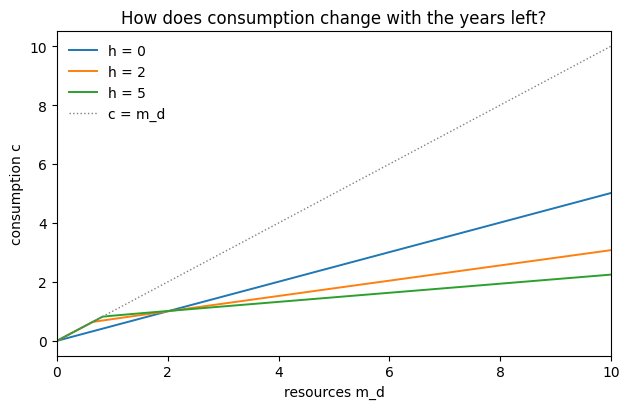

In [20]:
tool.plot_functions({"h = 0": (solved_b[0]["cons"].grid[up_to_10], solved_b[0]["cons"].policy["c"][up_to_10]),
                     "h = 2": (solved_b[2]["cons"].grid[up_to_10], solved_b[2]["cons"].policy["c"][up_to_10]),
                     "h = 5": (solved_b[5]["cons"].grid[up_to_10], solved_b[5]["cons"].policy["c"][up_to_10])},
                    xlabel="resources m_d", ylabel="consumption c", diagonal="c = m_d", xlim=(0, 10),
                    title="How does consumption change with the years left?")

With one year left the household does not consume everything, since the terminal step values its savings: it maximizes $u(\mathrm{c}) + \beta u(\mathrm{m}_d - \mathrm{c})$ and so consumes the share $1/(1 + \beta^{1/\rho})$ of its resources. With more years left the rule lies above the one-year rule at low resources and below it higher up; at $h = 2$ and 5 it lies on the line $\mathrm{c} = \mathrm{m}_d$ at the lowest resources shown, where the borrowing limit binds. The next cell computes that share from the stages' calibration and names it `share_0`.

In [21]:
share_0 = 1 / (1 + model_b["periods"][0]["stages"]["disc"].par["β"].value ** (1 / ending.par["ρ"].value))

The next cell marks resources from 1 to 10, where the rule is compared with it.

In [22]:
from_1_to_10 = (solved_b[0]["cons"].grid >= 1.0) & (solved_b[0]["cons"].grid <= 10.0)

The rule departs from the share only through interpolation of the terminal table. Read at the table's own points, the marginal value gives exactly the share. The consumption rule reads it at the points of the savings grid, each within `a_min` of a point of the table, by linear interpolation between points $\Delta$ apart at savings $\mathrm{a}$. To first order, that interpolation moves $\mathrm{c}/\mathrm{m}_d$ from the share by at most `a_min` times $\Delta(\rho + 1)/(8\mathrm{a}^2)$, which is below `a_min` because $\Delta < 8\mathrm{a}^2/(\rho + 1)$ at the savings that resources from 1 to 10 leave.

| Compared | Largest difference | Tolerance | Reason |
|---|---|---|---|
| $\mathrm{c}/\mathrm{m}_d$ at $h = 0$ and `share_0` | `deviation_0`, below | `a_min` | interpolation of the terminal table, to first order |

The next cell computes the largest deviation.

In [23]:
deviation_0 = float(np.max(np.abs(solved_b[0]["cons"].policy["c"][from_1_to_10] / solved_b[0]["cons"].grid[from_1_to_10] - share_0)))

The share, the deviation and the tolerance, which the assertion restates:

In [24]:
assert deviation_0 <= ending.settings["a_min"].value
share_0, deviation_0, ending.settings["a_min"].value

(0.5017009098771079, 7.798083290211366e-10, 1e-06)

The next cell draws the risky share at the same $h$, on capital up to 50.

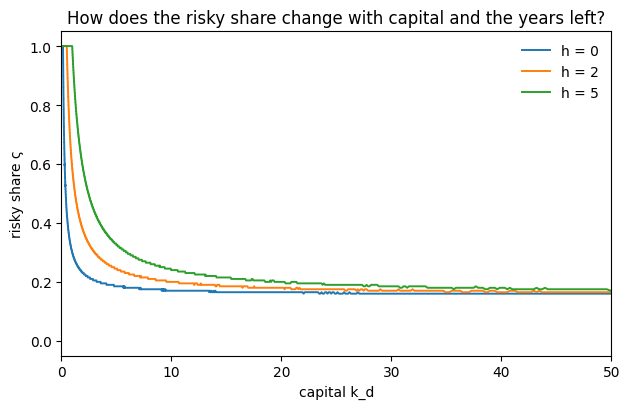

In [25]:
tool.plot_functions({"h = 0": (solved_b[0]["port"].grid, solved_b[0]["port"].policy["varsigma"]),
                     "h = 2": (solved_b[2]["port"].grid, solved_b[2]["port"].policy["varsigma"]),
                     "h = 5": (solved_b[5]["port"].grid, solved_b[5]["port"].policy["varsigma"])},
                    xlabel="capital k_d", ylabel="risky share ς", xlim=(0, 50),
                    title="How does the risky share change with capital and the years left?")

The share is highest at small capital, where next year's resources are mostly income, and falls as capital grows; more years of income left raise it.

## The consumption-first order

The next cell solves `model_e` from the same table by the endogenous-grid method and the share search (`egm`, `share_search` and `normal_nodes`, of `applications/cons-port/declaration/methods/cons.yml` and `applications/cons-port/declaration/methods/port.yml`) over six periods, as `solved_e`.

In [26]:
solved_e = tool.solve_trellis(model_e, terminal)

The next cell draws consumption at $h = 5$ in both orders.

In [27]:
tool.plot_functions({"portfolio first": (solved_b[5]["cons"].grid[up_to_10], solved_b[5]["cons"].policy["c"][up_to_10]),
                     "consumption first": (solved_e[5]["cons"].grid[up_to_10], solved_e[5]["cons"].policy["c"][up_to_10])},
                    xlabel="resources m_d", ylabel="consumption c", diagonal="c = m_d", xlim=(0, 10),
                    title="Does the order of the stages change consumption?")

IndexError: list index out of range

The rules differ because the orders end differently, not because consumption begins with other information: after the last consumption decision the portfolio-first order values the savings at once, and the consumption-first order invests them once more and receives one more draw of the return and of income, and the terminal value is taken on the resources those draws give.

The next cell draws the risky share at $h = 5$ in both orders.

In [28]:
tool.plot_functions({"portfolio first": (solved_b[5]["port"].grid, solved_b[5]["port"].policy["varsigma"]),
                     "consumption first": (solved_e[5]["port"].grid, solved_e[5]["port"].policy["varsigma"])},
                    xlabel="capital k_d", ylabel="risky share ς", xlim=(0, 50),
                    title="Does the order of the stages change the risky share?")

IndexError: list index out of range

The two shares nearly coincide at every level of capital shown. The orders differ in how the last year ends, so at $h = 5$ they solve different problems, and the comparison states how near the shares are rather than an identity: within ten candidate spacings of the share search, $10/(n_\varsigma - 1)$. Both orders store the share on the same grid of capital.

| Compared | Largest difference | Tolerance | Reason |
|---|---|---|---|
| the risky share at $h = 5$ on capital up to 50, portfolio first and consumption first | `share_gap`, below | $10/(n_\varsigma - 1)$ | the orders differ in the last year's ending; ten candidate spacings state what nearly means |

The next cell marks capital up to 50.

In [29]:
up_to_50 = solved_b[5]["port"].grid <= 50.0

The next cell computes the largest difference.

In [30]:
share_gap = float(np.max(np.abs(solved_b[5]["port"].policy["varsigma"][up_to_50] - solved_e[5]["port"].policy["varsigma"][up_to_50])))

IndexError: list index out of range

The difference and the tolerance, which the assertion restates:

In [31]:
assert share_gap <= 10 / (model_b["periods"][0]["stages"]["port"].settings["n_ς"].value - 1)
share_gap, 10 / (model_b["periods"][0]["stages"]["port"].settings["n_ς"].value - 1)

NameError: name 'share_gap' is not defined

## One order from the other

Write $P$, $D$ and $C$ for the operators of the portfolio, discount and consumption stages, each mapping the value a stage continues to into its arrival value. A portfolio-first period applies $D$, $C$, then $P$; a consumption-first period $P$, $D$, then $C$. Hence $(P \circ C \circ D)^6 = P \circ (C \circ D \circ P)^5 \circ C \circ D$: for value functions the year boundary changes nothing. The tool's `stage_operator` gives a stage occurrence's operator; the next cell names the portfolio stage's `port_step`.

In [32]:
port_step = tool.stage_operator(model_b["periods"][0]["stages"]["port"])

The next cell gives the discount stage's operator, `disc_step`.

In [33]:
disc_step = tool.stage_operator(model_b["periods"][0]["stages"]["disc"])

The next cell gives the consumption stage's operator, `cons_step`.

In [34]:
cons_step = tool.stage_operator(model_b["periods"][0]["stages"]["cons"])

The next cell applies $C \circ D$ to the terminal table and solves from it the last five periods of `model_e`, $h = 0$ to 4, by the endogenous-grid method and the share search (`egm`, `share_search` and `normal_nodes`, of `applications/cons-port/declaration/methods/cons.yml` and `applications/cons-port/declaration/methods/port.yml`), as `five_e`.

In [35]:
five_e = tool.solve_trellis({"periods": model_e["periods"][:5], "inter_connectors": model_e["inter_connectors"][:4]},
                            cons_step(disc_step(terminal)))

By the identity above, $P$ applied to `five_e` at $h = 4$ and the portfolio stage of `solved_b` at $h = 5$ are the same operators applied in the same sequence on the same grids, so the two agree exactly.

| Compared | Largest difference | Tolerance | Reason |
|---|---|---|---|
| $P$ applied to `five_e` at $h = 4$, and the portfolio stage of `solved_b` at $h = 5$ | `recovered`, below | 0 | the same operators in the same sequence on the same grids |

The next cell computes the largest difference.

In [36]:
recovered = float(np.max(np.abs(port_step(five_e[4]["cons"]).values - solved_b[5]["port"].values)))

IndexError: list index out of range

It is zero, as the assertion restates.

In [37]:
assert recovered == 0.0
recovered

NameError: name 'recovered' is not defined

## One stage's method changed

`trellis.port-cons-vfi.yml` changes only the consumption stage's binding files: a grid search over candidate consumption levels, `!vfi` on the decision builder `cntn_to_dcsn`, handler `cons-port:consumption_search`, the function `consumption_search`.

In [38]:
print(open("applications/cons-port/declaration/methods/cons_vfi.yml").read())

stage: cons
# The consumption stage's methods under value function iteration, on the stage file
# declaration/stages/cons/cons.bl, which writes the maximization alone: a
# grid search over candidate consumption levels on the backward decision builder, realized by the function
# consumption_search of cons_port_tool.py, and the value represented at the decision builder's Evaluation,
# cntn_to_dcsn.evaluate.value, by the basis !Linear on the grid of resources m that the setting grid names by its
# kind, !Cartesian, with its order and bounds, the settings n_m, m_min and m_max, beside it.
# No block is bound: the search reads no marginal value of the continuation and takes the marginal value of the
# decision as the difference quotient of the values.
methods:
  - on: cntn_to_dcsn
    method: !vfi
    handler: cons-port:consumption_search
  - on: cntn_to_dcsn.evaluate.value
    method: !Linear
    settings: {grid: !Cartesian, orders: {m: n_m}, bounds: {m: [m_min, m_max]}}



The next cell reads the trellis file.

In [39]:
syntactic_v = load_trellis("applications/cons-port/declaration/trellis.port-cons-vfi.yml")

Binding the built model's methods and settings anew from it gives `model_v`.

In [40]:
model_v = configure_trellis(methodize_trellis(model_b, syntactic_v), syntactic_v)

`changed_positions` lists the positions whose stage occurrence is new: the consumption stage at its six positions, every other one copied.

In [41]:
changed_positions(model_b, model_v)

[(0, 'cons'), (1, 'cons'), (2, 'cons'), (3, 'cons'), (4, 'cons'), (5, 'cons')]

The consumption stage's settings now give the number of candidates, `n_c`:

In [42]:
model_v["periods"][0]["stages"]["cons"].settings

name          value    read at                  by       grid
grid_spacing  expmult
n_m           64000    cntn_to_dcsn:Evaluation  !Linear  !Cartesian
m_min         0.01     cntn_to_dcsn:Evaluation  !Linear  !Cartesian
m_max         2000.0   cntn_to_dcsn:Evaluation  !Linear  !Cartesian
n_a           16000
a_min         1e-06
a_max         2000.0
n_toll        200
n_init        20041
n_c           200

The next cell solves `model_v` from the same table over six periods, consumption by the grid search (`applications/cons-port/declaration/methods/cons_vfi.yml`, `consumption_search`) and the portfolio stage as before (`applications/cons-port/declaration/methods/port.yml`, `share_search`, `normal_nodes`), as `solved_v`.

In [43]:
solved_v = tool.solve_trellis(model_v, terminal)

The search chooses among $n_c$ candidates evenly spaced on $(0, \mathrm{m}_d)$, so, to first order in the spacing, its choice lies within half a spacing, $\mathrm{m}_d/(2(n_c - 1))$, of the endogenous-grid rule. The spacing is widest at $\mathrm{m}_d = 10$, which gives the tolerance.

| Compared | Largest difference | Tolerance | Reason |
|---|---|---|---|
| consumption at $h = 5$ on resources from 1 to 10, by the search and by `egm` | `search_gap`, below | $10/(2(n_c - 1))$ | half the widest candidate spacing, to first order in the spacing |

The next cell computes the largest difference.

In [44]:
search_gap = float(np.max(np.abs(solved_v[5]["cons"].policy["c"][from_1_to_10] - solved_b[5]["cons"].policy["c"][from_1_to_10])))

The difference and the tolerance, which the assertion restates:

In [45]:
assert search_gap <= 10.0 / (2 * (model_v["periods"][0]["stages"]["cons"].settings["n_c"].value - 1))
search_gap, 10.0 / (2 * (model_v["periods"][0]["stages"]["cons"].settings["n_c"].value - 1))

(0.023583060483653995, 0.02512562814070352)

The application's acceptance test, `applications/cons-port/code/tests/test_cons_port_acceptance.py`, holds the terminal value and the rebinding shown here and reproduces the fixed reference of an earlier implementation.